[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_5_Regresion_Logistica_DILI.ipynb)

# Fase 5. Regresión logística para la clase DILI

Uso la etiqueta DILI como variable binaria: 1 indica clasificación positiva y 0 negativa. De los descriptores de RDKit, selecciono en train hasta doce con mayor asociación de Spearman, excluyendo MolLogP y LipinskiViolations. Limito el número para mantener un modelo interpretable y reduzco redundancia con correlación por pares y VIF. Evalúo el rendimiento en test y comparo sus métricas con train.


In [1]:
# Instalo las librerías que usaré para la regresión y su gráfico de odds ratios.\n%pip -q install statsmodels forestplot

## 5.1. Lectura de los datos

In [2]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
datos = dilist.merge(estructuras, on='CompoundName', how='left')  # Uno las etiquetas con el estado de búsqueda.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

He cargado los datos del repositorio: /workspace/scratch/b597cb51ba0f/run_outputs/datos_dili
Descriptores numéricos disponibles: 218


## 5.2. Selección, colinealidad y ajuste

La lista inicial procede de la asociación bivariada con DILI en train; el máximo de doce acota el número de parámetros frente al tamaño de muestra. El filtro de Spearman elimina predictores muy parecidos entre sí y el VIF detecta redundancia multivariante. Retiro iterativamente el VIF más alto hasta que todos quedan en 5 o menos. Ajusto imputación y escalado solo con train y aplico esos parámetros a test.


In [3]:
# Importo herramientas para preparar y ajustar la regresión logística.
from sklearn.impute import SimpleImputer  # Completo posibles valores ausentes.
from sklearn.preprocessing import StandardScaler  # Estandarizo los predictores.
import statsmodels.api as sm  # Ajusto el modelo y obtengo intervalos y valores p.

# Selecciono descriptores sin MolLogP ni incumplimientos que dependen de esa variable.
columnas_excluir = ['MolLogP', 'LipinskiViolations', 'DILI', 'DILIST_ID']  # Evito LogP, la clase y los identificadores.
predictores = [variable for variable in DESCRIPTORES if variable not in columnas_excluir and train_df[variable].nunique(dropna=True) > 1]  # Uso descriptores no constantes.
print('Descriptores candidatos:', len(predictores))  # Informo el tamaño inicial del catálogo.

# Reviso las asociaciones bivariadas con DILI usando solo entrenamiento.
asociacion = train_df[predictores + ['DILI']].corr(method='spearman')['DILI'].drop('DILI').dropna().abs().sort_values(ascending=False)  # Ordeno la asociación absoluta.
candidatos = asociacion.head(12).index.tolist()  # Tomo los doce descriptores más asociados en train.
print('Candidatos con mayor asociación a DILI:', len(candidatos))  # Muestro el número seleccionado.

# Quito variables redundantes entre los candidatos.
correlacion = train_df[candidatos].corr(method='spearman').abs()  # Calculo correlación absoluta.
seleccionados = []  # Creo la lista de predictores finales.
for variable in candidatos:  # Reviso candidatos en orden de asociación.
    if not any(correlacion.loc[variable, otra] >= 0.90 for otra in seleccionados):  # Compruebo redundancia.
        seleccionados.append(variable)  # Conservo variables por debajo del umbral.
print('Descriptores finales tras quitar redundancia:', seleccionados)  # Informo el conjunto final.

# Muestro el criterio de selección y el tipo de propiedad de cada descriptor.
descripcion = {'FractionCSP3': 'proporción de carbonos sp3', 'BCUT2D_LOGPLOW': 'topología ponderada por contribuciones de LogP', 'fr_Al_OH': 'recuento de grupos hidroxilo alifáticos', 'SMR_VSA6': 'superficie agrupada por refractividad molar', 'SlogP_VSA2': 'superficie agrupada por contribuciones de LogP', 'fr_Ndealkylation1': 'motivo estructural de N-desalquilación', 'BCUT2D_MRHI': 'topología ponderada por refractividad molar', 'fr_quatN': 'recuento de nitrógenos cuaternarios', 'PEOE_VSA1': 'superficie agrupada por carga parcial', 'NumAtomStereoCenters': 'número de centros estereogénicos', 'VSA_EState9': 'superficie agrupada por estado electrotopológico', 'BCUT2D_CHGLO': 'topología ponderada por carga parcial'}  # Describo los predictores seleccionados.
tabla_seleccion = pd.DataFrame({'descriptor': seleccionados, 'rho_Spearman_train': train_df[seleccionados + ['DILI']].corr(method='spearman')['DILI'].loc[seleccionados].values, 'tipo de característica': [descripcion.get(variable, 'descriptor molecular RDKit') for variable in seleccionados]})  # Uno su significado y asociación.
display(tabla_seleccion.round(3))  # Muestro por qué quedaron en el modelo.
print('Los selecciono por su asociación bivariada más alta en train; después retiro redundancia entre predictores. Son candidatos exploratorios, no causas ni una lista universal de hepatotoxicidad.')  # Justifico la elección.


# Preparo la variable objetivo y ajusto transformaciones usando solo train.
y_train = train_df['DILI'].astype(int)  # Defino las etiquetas de entrenamiento.
y_test = test_df['DILI'].astype(int)  # Defino las etiquetas de prueba.
imputador = SimpleImputer(strategy='median')  # Creo imputación por mediana.
imputador.fit(train_df[seleccionados])  # Aprendo medianas solo en train.
X_train_imp = imputador.transform(train_df[seleccionados])  # Transformo train.
X_test_imp = imputador.transform(test_df[seleccionados])  # Aplico medianas de train a test.
escalador = StandardScaler()  # Creo el escalador.
escalador.fit(X_train_imp)  # Aprendo medias y desviaciones solo con train.
X_train = escalador.transform(X_train_imp)  # Estandarizo train.
X_test = escalador.transform(X_test_imp)  # Transformo test con el mismo ajuste.

# Organizo las matrices con nombres para interpretar cada coeficiente.
X_train_df = pd.DataFrame(X_train, columns=seleccionados, index=train_df.index)  # Etiqueto las columnas de train.
X_test_df = pd.DataFrame(X_test, columns=seleccionados, index=test_df.index)  # Etiqueto las columnas de test.
X_train_sm = sm.add_constant(X_train_df, has_constant='add')  # Añado el intercepto.
X_test_sm = sm.add_constant(X_test_df, has_constant='add')  # Añado el mismo intercepto a test.

# Reviso colinealidad multivariante en los predictores estandarizados de train.
from statsmodels.stats.outliers_influence import variance_inflation_factor  # Calculo VIF.
variables_retiradas_vif = []  # Guardo los predictores eliminados por redundancia.
while X_train_df.shape[1] > 2:  # Mantengo al menos dos variables explicativas.
    tabla_vif = pd.DataFrame({'descriptor': X_train_df.columns, 'VIF': [variance_inflation_factor(X_train_df.values, i) for i in range(X_train_df.shape[1])]})  # Calculo el VIF de cada columna.
    if tabla_vif['VIF'].max() <= 5:  # Uso cinco como umbral de revisión.
        break  # Paro cuando los valores quedan bajo el umbral.
    fila_maxima = tabla_vif['VIF'].idxmax()  # Localizo el VIF más alto.
    variable_retirada = tabla_vif.loc[fila_maxima, 'descriptor']  # Identifico el predictor redundante.
    variables_retiradas_vif.append((variable_retirada, tabla_vif.loc[fila_maxima, 'VIF']))  # Registro el predictor y su VIF.
    X_train_df = X_train_df.drop(columns=variable_retirada)  # Quito la variable de train.
    X_test_df = X_test_df.drop(columns=variable_retirada)  # Aplico la misma eliminación a test.
    seleccionados.remove(variable_retirada)  # Actualizo la lista del modelo.
tabla_vif = pd.DataFrame({'descriptor': X_train_df.columns, 'VIF': [variance_inflation_factor(X_train_df.values, i) for i in range(X_train_df.shape[1])]})  # Recalculo VIF finales.
display(tabla_vif.sort_values('VIF', ascending=False).round(2))  # Muestro los predictores retenidos.
print('Predictores retirados por VIF:', [(nombre, round(float(vif), 2)) for nombre, vif in variables_retiradas_vif] if variables_retiradas_vif else 'ninguno')  # Explico qué cambió.
print('El VIF final de cada descriptor queda en 5 o menos; este umbral es orientativo y se usa para reducir colinealidad.')  # Justifico el criterio.
X_train_sm = sm.add_constant(X_train_df, has_constant='add')  # Actualizo train tras el filtro.
X_test_sm = sm.add_constant(X_test_df, has_constant='add')  # Actualizo test con las mismas columnas.

# Pondero las clases de train para compensar su distinta frecuencia.
pesos = np.where(y_train == 1, len(y_train) / (2 * (y_train == 1).sum()), len(y_train) / (2 * (y_train == 0).sum()))  # Calculo pesos equilibrados.
modelo = sm.GLM(y_train, X_train_sm, family=sm.families.Binomial(), freq_weights=pesos).fit()  # Ajusto regresión logística ponderada.


Descriptores candidatos: 211
Candidatos con mayor asociación a DILI: 12
Descriptores finales tras quitar redundancia: ['FractionCSP3', 'BCUT2D_LOGPLOW', 'fr_Al_OH', 'SMR_VSA6', 'SlogP_VSA2', 'fr_Ndealkylation1', 'BCUT2D_MRHI', 'fr_quatN', 'PEOE_VSA1', 'NumAtomStereoCenters', 'VSA_EState9', 'BCUT2D_CHGLO']
Los selecciono por su asociación bivariada más alta en train; después retiro redundancia entre predictores. Son candidatos exploratorios, no causas ni una lista universal de hepatotoxicidad.
Predictores retirados por VIF: [('SlogP_VSA2', 38.79), ('PEOE_VSA1', 9.0)]
El VIF final de cada descriptor queda en 5 o menos; este umbral es orientativo y se usa para reducir colinealidad.


,descriptor,rho_Spearman_train,tipo de característica
0,FractionCSP3,-0.211,proporción de carbonos sp3
1,BCUT2D_LOGPLOW,0.175,topología ponderada por contribuciones de LogP
2,fr_Al_OH,-0.170,recuento de grupos hidroxilo alifáticos
3,SMR_VSA6,-0.169,superficie agrupada por refractividad molar
4,SlogP_VSA2,-0.168,superficie agrupada por contribuciones de LogP
5,fr_Ndealkylation1,-0.166,motivo estructural de N-desalquilación
6,BCUT2D_MRHI,0.163,topología ponderada por refractividad molar
7,fr_quatN,-0.153,recuento de nitrógenos cuaternarios
8,PEOE_VSA1,-0.146,superficie agrupada por carga parcial
9,NumAtomStereoCenters,-0.143,número de centros estereogénicos


,descriptor,VIF
1,BCUT2D_LOGPLOW,3.92
9,BCUT2D_CHGLO,3.73
7,NumAtomStereoCenters,2.39
2,fr_Al_OH,2.06
0,FractionCSP3,1.49
3,SMR_VSA6,1.45
4,fr_Ndealkylation1,1.35
8,VSA_EState9,1.31
6,fr_quatN,1.31
5,BCUT2D_MRHI,1.13


## 5.3. Odds ratios e intervalos de confianza

Represento con forestplot los odds ratios, sus intervalos de confianza del 95 % y los valores p. Como los predictores están estandarizados, cada OR corresponde a un aumento de una desviación estándar, manteniendo constantes los demás predictores. La línea vertical marca OR = 1, valor de referencia sin cambio en las odds.


BCUT2D_CHGLO: OR = 0.70, cambio estimado de odds -30.2% por una desviación estándar; el IC queda a un lado de 1.
BCUT2D_LOGPLOW: OR = 1.58, cambio estimado de odds +57.5% por una desviación estándar; el IC queda a un lado de 1.
Estos son efectos ajustados dentro de este modelo y no implican causalidad; la selección previa hace que los valores p sean exploratorios.


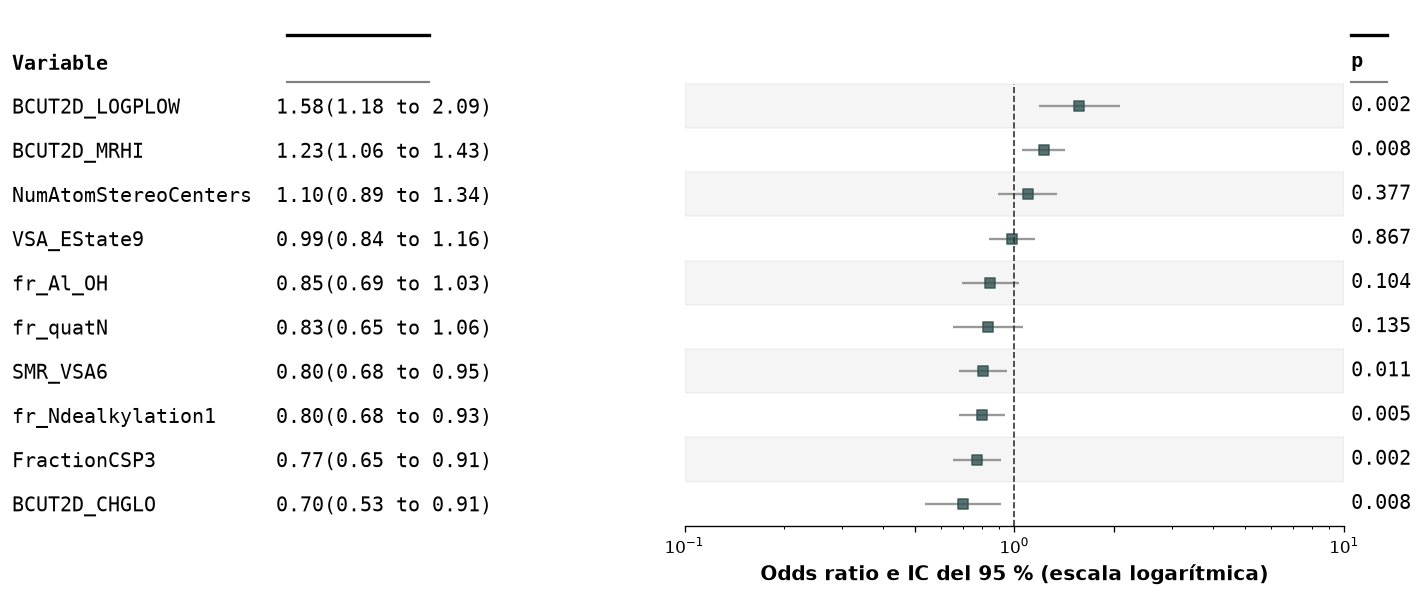

In [4]:
# Importo las herramientas para representar e interpretar odds ratios.
import matplotlib.pyplot as plt  # Dibujo el forest plot.
import forestplot as fp  # Uso la librería solicitada para el forest plot.

# Calculo odds ratios e intervalos de confianza del 95 %.
intervalos = modelo.conf_int().loc[seleccionados]  # Extraigo intervalos de los predictores retenidos.
odds = pd.DataFrame({'descriptor': seleccionados, 'odds_ratio': np.exp(modelo.params.loc[seleccionados].values), 'ic_inferior': np.exp(intervalos[0].values), 'ic_superior': np.exp(intervalos[1].values), 'p_value': modelo.pvalues.loc[seleccionados].values})  # Organizo estimaciones e incertidumbre.
odds['p_text'] = odds['p_value'].apply(lambda p: '<0.001' if p < 0.001 else f'{p:.3f}')  # Presento p pequeños sin redondearlos a cero.

# Muestro una figura con estimaciones, intervalos y valores p.
figura, eje = plt.subplots(figsize=(12, max(5, 0.42 * len(odds))))  # Ajusto el tamaño al número de predictores.
fp.forestplot(dataframe=odds, estimate='odds_ratio', ll='ic_inferior', hl='ic_superior', varlabel='descriptor', pval=None, rightannote=['p_text'], right_annoteheaders=['p'], logscale=True, sort=True, xlabel='Odds ratio e IC del 95 % (escala logarítmica)', xticks=[0.1, 0.5, 1, 2, 10], decimal_precision=2, color_alt_rows=True, xline=1, xlinestyle='--', table=True, ylabel=' ', ax=eje)  # Dibujo el forest plot sin marcas superpuestas.
plt.tight_layout()  # Ajusto los nombres y el eje.
plt.show()  # Presento los odds ratios.

# Comento los dos odds ratios extremos calculados.
orden_odds = odds.sort_values('odds_ratio')  # Ordeno los OR.
for fila in [orden_odds.iloc[0], orden_odds.iloc[-1]]:  # Reviso el OR menor y el mayor.
    cambio = 100 * (fila['odds_ratio'] - 1)  # Calculo el cambio porcentual en odds.
    evidencia = 'el IC queda a un lado de 1' if fila['ic_superior'] < 1 or fila['ic_inferior'] > 1 else 'el IC incluye 1'  # Valoro si el intervalo cruza la referencia.
    print(f"{fila['descriptor']}: OR = {fila['odds_ratio']:.2f}, cambio estimado de odds {cambio:+.1f}% por una desviación estándar; {evidencia}.")  # Interpreto el resultado mostrado.
print('Estos son efectos ajustados dentro de este modelo y no implican causalidad; la selección previa hace que los valores p sean exploratorios.')  # Aclaro el alcance inferencial.


## Lectura de los odds ratios

Un OR mayor que 1 indica odds estimadas más altas de una etiqueta DILI positiva y un OR menor que 1 indica odds menores, para un aumento de una desviación estándar del descriptor. Si el intervalo cruza 1, la estimación es compatible con ausencia de asociación en este modelo. La selección de predictores se hizo con train, por lo que los valores p sirven como lectura exploratoria.


## 5.4. Rendimiento de clasificación en train y test

Comparo accuracy, precision, sensibilidad (recall), especificidad, F1 y AUC-ROC entre las dos particiones. En test, muestro también la matriz de confusión y la curva ROC en una misma figura para relacionar los indicadores con los errores observados.


La diferencia train-test de AUC-ROC es -13.4 puntos; la de recall es -9.4 puntos.
En test, especificidad = 0.473: el modelo identifica correctamente esa proporción de negativos.
AUC-ROC = 0.556; valores cercanos a 0,5 indican poca capacidad de separar las dos clases.


,train (%),test (%),diferencia test-train (p.p.)
accuracy,64.2,53.6,-10.6
precision,72.9,63.6,-9.3
sensibilidad,67.0,57.5,-9.4
especificidad,59.8,47.3,-12.6
F1,69.8,60.4,-9.4
AUC-ROC,69.0,55.6,-13.4


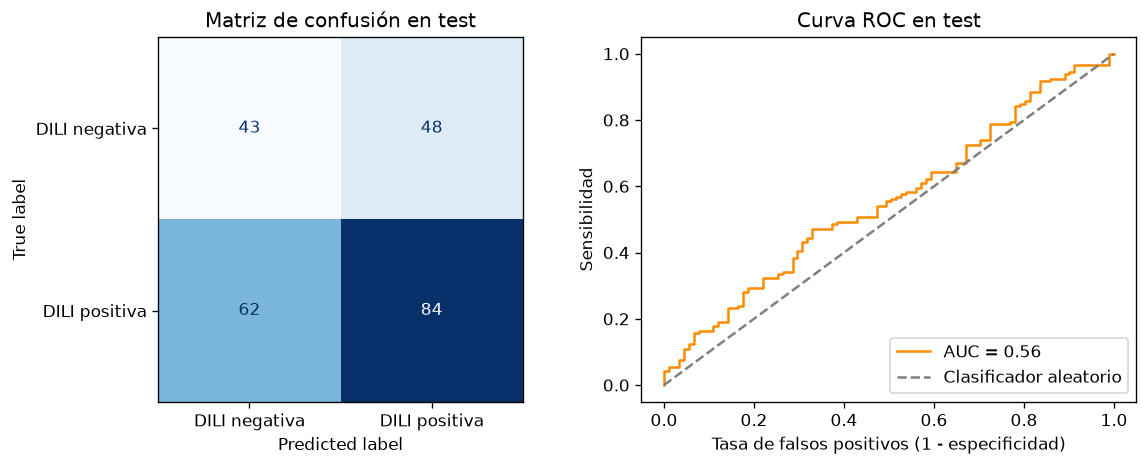

In [5]:
# Importo las métricas necesarias para comparar clasificación y curvas ROC.
import matplotlib.pyplot as plt  # Dibujo la matriz y la curva ROC en una figura.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve  # Calculo evaluación binaria.

# Estimo probabilidades en las dos particiones con el modelo ya ajustado.
prob_train = modelo.predict(X_train_sm)  # Predigo probabilidades en train.
prob_test = modelo.predict(X_test_sm)  # Predigo probabilidades en test.
pred_train = (prob_train >= 0.5).astype(int)  # Clasifico train con umbral 0,5.
pred_test = (prob_test >= 0.5).astype(int)  # Clasifico test con el mismo umbral.

# Calculo especificidad además de las métricas de clasificación solicitadas.
def calcular_metricas(y_real, y_predicho, probabilidad):  # Defino el resumen para una partición.
    tn, fp, fn, tp = confusion_matrix(y_real, y_predicho, labels=[0, 1]).ravel()  # Extraigo verdaderos y falsos positivos y negativos.
    especificidad = tn / (tn + fp) if (tn + fp) else 0  # Calculo la tasa de verdaderos negativos.
    return {'accuracy': accuracy_score(y_real, y_predicho), 'precision': precision_score(y_real, y_predicho, zero_division=0), 'sensibilidad': recall_score(y_real, y_predicho, zero_division=0), 'especificidad': especificidad, 'F1': f1_score(y_real, y_predicho, zero_division=0), 'AUC-ROC': roc_auc_score(y_real, probabilidad)}  # Devuelvo los indicadores.
metricas_train = calcular_metricas(y_train, pred_train, prob_train)  # Resumo train.
metricas_test = calcular_metricas(y_test, pred_test, prob_test)  # Resumo test.
comparacion = pd.DataFrame({'train (%)': {k: 100 * v for k, v in metricas_train.items()}, 'test (%)': {k: 100 * v for k, v in metricas_test.items()}})  # Organizo los porcentajes.
comparacion['diferencia test-train (p.p.)'] = comparacion['test (%)'] - comparacion['train (%)']  # Calculo diferencia en puntos porcentuales.
display(comparacion.round(1))  # Muestro métricas y brecha de generalización.
print(f"La diferencia train-test de AUC-ROC es {100 * (metricas_test['AUC-ROC'] - metricas_train['AUC-ROC']):+.1f} puntos; la de recall es {100 * (metricas_test['sensibilidad'] - metricas_train['sensibilidad']):+.1f} puntos.")  # Comento las brechas principales.

# Calculo la matriz de confusión y la curva ROC para test.
matriz_test = confusion_matrix(y_test, pred_test, labels=[0, 1])  # Cuento TN, FP, FN y TP en test.
fpr, tpr, umbrales = roc_curve(y_test, prob_test)  # Calculo tasas para dibujar ROC.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # Creo dos paneles de evaluación.
ConfusionMatrixDisplay(matriz_test, display_labels=['DILI negativa', 'DILI positiva']).plot(ax=axes[0], cmap='Blues', colorbar=False)  # Muestro errores por clase.
axes[0].set_title('Matriz de confusión en test')  # Titulo el primer panel.
axes[1].plot(fpr, tpr, color='darkorange', label=f"AUC = {metricas_test['AUC-ROC']:.2f}")  # Dibujo la curva ROC.
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Clasificador aleatorio')  # Añado la referencia aleatoria.
axes[1].set_xlabel('Tasa de falsos positivos (1 - especificidad)')  # Etiqueto el eje horizontal.
axes[1].set_ylabel('Sensibilidad')  # Etiqueto el eje vertical.
axes[1].set_title('Curva ROC en test')  # Titulo el segundo panel.
axes[1].legend(loc='lower right')  # Identifico curva y referencia.
plt.tight_layout()  # Ajusto los paneles.
plt.show()  # Presento ambas evaluaciones juntas.
print(f"En test, especificidad = {metricas_test['especificidad']:.3f}: el modelo identifica correctamente esa proporción de negativos.")  # Interpreto la especificidad.
print(f"AUC-ROC = {metricas_test['AUC-ROC']:.3f}; valores cercanos a 0,5 indican poca capacidad de separar las dos clases.")  # Interpreto la discriminación.


## Interpretación de la evaluación

La tabla expresa las métricas en porcentaje y la diferencia test-train en puntos porcentuales. Comparo sensibilidad y especificidad porque los errores de falsos negativos y falsos positivos tienen lecturas distintas. La curva ROC resume la separación entre clases a distintos umbrales; la matriz muestra los errores al umbral de 0,5 utilizado aquí. La brecha entre train y test ayuda a valorar la generalización.
